In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
%pip install ultralytics
from ultralytics import YOLO

model = YOLO('yolov8m.pt')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 17.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 116.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 93.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 53.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 13.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 82.0 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5.82
    Uninstalling

100%|██████████| 49.7M/49.7M [00:00<00:00, 228MB/s]


In [5]:
dataset = "/content/drive/MyDrive/vehicle_detection/merged_dataset/data.yaml"

## Baseline Model Evaluation: YOLOv8m on Custom Validation Set

This evaluation measures the performance of the standard, pre-trained YOLOv8 medium model (`yolov8m.pt`) directly on our specific validation dataset.

**Key Points:**

*   **Model:** We used the `yolov8m.pt` model weights provided by Ultralytics. These weights were obtained by training the model on the large-scale COCO dataset, which contains a wide variety of common objects.
*   **No Transfer Learning:** Crucially, this evaluation was performed *without* any prior training or fine-tuning on our custom dataset. We are essentially testing how well the general knowledge learned from COCO transfers to our specific task "out of the box".
*   **Dataset:** The evaluation was run using the validation split defined in the configuration file (labeled data)
*   **Purpose:** The results from this run serve as our **baseline**. This is the performance level we are trying to "beat" through techniques like transfer learning and fine-tuning on our own data.

**Results:**

The validation process yielded the following metrics:

             Class     Images  Instances      Box(P          R      mAP50  mAP50-95)
               all        746       3211      0.747      0.468      0.554      0.396
               car        627       3211      0.747      0.468      0.554      0.396



*   **mAP50:** 0.554
*   **mAP50-95:** 0.396

These baseline scores indicate the starting performance level. While the model shows some capability (especially at the lower IoU threshold of 0.50), there is significant room for improvement, particularly in localization precision (as shown by the lower mAP50-95 score). Our subsequent efforts involving transfer learning aim to substantially increase these metrics by adapting the model specifically to our dataset's characteristics.




In [ ]:
dataset_2 = "/content/drive/MyDrive/vehicle_detection/merged_dataset_coco_car/base_case_data.yaml"
metrics = model.val(data=dataset_2)

Ultralytics 8.3.124 🚀 Python-3.11.12 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
YOLOv8m summary (fused): 92 layers, 25,886,080 parameters, 0 gradients, 78.9 GFLOPs


100%|██████████| 755k/755k [00:00<00:00, 13.0MB/s]


val: Fast image access ✅ (ping: 0.9±0.6 ms, read: 0.1±0.0 MB/s, size: 36.0 KB)


val: Scanning /content/drive/MyDrive/vehicle_detection/merged_dataset_coco_car/valid/labels.cache... 736 images, 119 backgrounds, 0 corrupt: 100%|██████████| 746/746 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 47/47 [00:17<00:00,  2.66it/s]


                   all        746       3211      0.747      0.468      0.554      0.396
                   car        627       3211      0.747      0.468      0.554      0.396
Speed: 0.7ms preprocess, 16.3ms inference, 0.0ms loss, 1.6ms postprocess per image
Results saved to runs/detect/val


In [ ]:
from ultralytics import YOLO
import os

model_path = 'yolov8m.pt'

run_name = 'yolov8m_base_eval_on_dataset_2_test'

if not os.path.exists(dataset_2):
    print(f"ERROR: Dataset YAML file not found at {dataset_2}")
else:
    print(f"\nEvaluating base model '{model_path}' on test split of dataset '{dataset_2}'...")
    model = YOLO(model_path)

    metrics = model.val(
        data=dataset_2,
        split='test',
        plots=True,
        name=run_name
    )

    print("\nBase model evaluation finished!")
    print("Metrics for the base model on dataset_2 test set:")
    print(f"  mAP50-95: {metrics.box.map:.4f}")
    print(f"  mAP50:    {metrics.box.map50:.4f}")



Evaluating base model 'yolov8m.pt' on test split of dataset '/content/drive/MyDrive/vehicle_detection/merged_dataset_coco_car/base_case_data.yaml'...


100%|██████████| 49.7M/49.7M [00:00<00:00, 267MB/s]


Ultralytics 8.3.127 🚀 Python-3.11.12 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
YOLOv8m summary (fused): 92 layers, 25,886,080 parameters, 0 gradients, 78.9 GFLOPs
val: Fast image access ✅ (ping: 0.7±0.4 ms, read: 0.1±0.0 MB/s, size: 42.9 KB)


val: Scanning /content/drive/MyDrive/vehicle_detection/merged_dataset_coco_car/test/labels... 737 images, 127 backgrounds, 0 corrupt: 100%|██████████| 747/747 [06:20<00:00,  1.96it/s]


val: New cache created: /content/drive/MyDrive/vehicle_detection/merged_dataset_coco_car/test/labels.cache


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 47/47 [00:22<00:00,  2.12it/s]


                   all        747       3302      0.731      0.509      0.592      0.427
                   car        620       3302      0.731      0.509      0.592      0.427
Speed: 1.1ms preprocess, 21.7ms inference, 0.0ms loss, 1.6ms postprocess per image
Results saved to runs/detect/yolov8m_base_eval_on_dataset_2_test

Base model evaluation finished!
Metrics for the base model on dataset_2 test set:
  mAP50-95: 0.4267
  mAP50:    0.5920


## Fine-Tuned Model Training: YOLOv8m with Custom Settings

This section details the training process where we fine-tuned the pre-trained YOLOv8 medium model (`yolov8m.pt`) on our custom dataset to improve performance beyond the baseline. This involved setting specific parameters and leveraging YOLOv8's built-in optimization features.

**Fine-Tuning Strategy & Parameters:**

Several explicit adjustments and automatic processes contributed to the fine-tuning:

**Explicit Settings:**

1.  **Transfer Learning Base:** We started with `yolov8m.pt`, leveraging the weights pre-trained on the COCO dataset. This provides a strong initial foundation of general visual understanding.
2.  **Increased Training Resolution (`imgsz=1024`):** The model was trained using input images resized to 1024x1024 pixels. This larger size allows the model to learn finer details, potentially leading to more precise object localization (better bounding boxes) and improving the mAP50-95 metric.
3.  **Adjusted Batch Size (`batch_size=8`):** Due to the increased memory requirements of the higher resolution, the batch size was set to 8 to ensure training could proceed within the available GPU memory.
4.  **Explicit Optimizer (`optimizer='AdamW'`):** We explicitly selected the AdamW optimizer, ensuring its use and allowing direct control over related parameters like learning rate and weight decay.
5.  **Reduced Initial Learning Rate (`lr0=0.005`):** A relatively low initial learning rate was chosen. For fine-tuning, smaller learning rates encourage more subtle adjustments to the existing pre-trained weights, helping refine performance without disrupting learned features.
6.  **Weight Decay (`weight_decay=0.0006`):** A small amount of weight decay was applied as a regularization technique to help prevent overfitting by penalizing large model weights.
7.  **Early Stopping (`patience=20`):** Training was configured to stop automatically if the primary validation metric did not improve for 20 consecutive epochs, saving computation time and preventing overfitting.
8.  **Training Duration (`epochs=75`):** The model was set to train for a maximum of 75 epochs, subject to the early stopping condition.

**Automatic ("Under the Hood") Fine-Tuning Mechanisms:**

YOLOv8 also employs several default mechanisms that aid the fine-tuning process:

1.  **Learning Rate Scheduling:** Although we set `lr0`, YOLOv8 automatically uses a scheduler (typically Cosine Annealing) to gradually decrease the learning rate from the initial value towards a much smaller final value over the 75 epochs. This allows for larger updates early on and finer adjustments later in training.
2.  **Warmup Phase:** Training usually starts with a brief warmup period (e.g., 3 epochs) where the learning rate ramps up from very low *to* our specified `lr0`. This stabilizes the initial phase of fine-tuning.
3.  **Default Data Augmentations:** Standard augmentations like horizontal flips, mosaic composition, and color space adjustments are applied randomly on-the-fly to the training batches. This acts as regularization, forcing the model to learn more robust features and improving its ability to generalize to unseen data.
4.  **Optimizer Internals:** The chosen AdamW optimizer uses default internal parameters (like beta values) that manage momentum and adaptive learning rates per parameter, helping it navigate the optimization process effectively.
5.  **Automatic Mixed Precision (AMP):** On compatible hardware, AMP is typically used automatically to speed up calculations and reduce memory usage without significantly impacting the final accuracy.

**Results:**

After fine-tuning with these combined explicit settings and automatic mechanisms, the best model achieved the following performance on the validation set:

             Class     Images  Instances      Box(P          R      mAP50  mAP50-95)
               all        746       3212       0.93      0.953       0.97        0.8

*   **mAP50:** 0.970
*   **mAP50-95:** 0.800

These results demonstrate a significant improvement over the baseline model (mAP50: 0.554, mAP50-95: 0.396), validating the effectiveness of the overall fine-tuning strategy in adapting the pre-trained model to our specific dataset and improving both detection and localization accuracy.




In [ ]:
from ultralytics import YOLO
import os

model = YOLO('yolov8m.pt')


num_epochs = 75
image_size = 1024
batch_size = 8
run_name = 'yolov8m_finetuned_1024_py'

print(f"Starting training with data from: {dataset}")
results = model.train(
    data=dataset,
    epochs=num_epochs,
    imgsz=image_size,
    batch=batch_size,
    name=run_name,
    optimizer='AdamW',
    patience=20,
    lr0=0.005,
    weight_decay=0.0006,

)

print("Training finished!")
print(f"Results saved to directory: {results.save_dir}")

Starting training with data from: /content/drive/MyDrive/vehicle_detection/merged_dataset/data.yaml
Ultralytics 8.3.125 🚀 Python-3.11.12 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: task=detect, mode=train, model=yolov8m.pt, data=/content/drive/MyDrive/vehicle_detection/merged_dataset/data.yaml, epochs=75, time=None, patience=20, batch=8, imgsz=1024, save=True, save_period=-1, cache=False, device=None, workers=8, project=None, name=yolov8m_finetuned_1024_run_py, exist_ok=False, pretrained=True, optimizer=AdamW, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, classes=None, retina_masks

100%|██████████| 5.35M/5.35M [00:00<00:00, 89.2MB/s]


AMP: checks passed ✅
train: Fast image access ✅ (ping: 2.9±5.1 ms, read: 0.1±0.0 MB/s, size: 38.4 KB)


train: Scanning /content/drive/MyDrive/vehicle_detection/merged_dataset/train/labels.cache... 3435 images, 517 backgrounds, 0 corrupt: 100%|██████████| 3435/3435 [00:00<?, ?it/s]


albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, method='weighted_average', num_output_channels=3), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))
val: Fast image access ✅ (ping: 0.4±0.1 ms, read: 27.1±8.1 MB/s, size: 39.0 KB)


val: Scanning /content/drive/MyDrive/vehicle_detection/merged_dataset/valid/labels.cache... 736 images, 118 backgrounds, 0 corrupt: 100%|██████████| 746/746 [00:00<?, ?it/s]


... (224 outputs left out)

                   all        746       3212      0.931       0.95      0.967      0.798



75 epochs completed in 6.819 hours.
Optimizer stripped from runs/detect/yolov8m_finetuned_1024_run_py/weights/last.pt, 52.1MB
Optimizer stripped from runs/detect/yolov8m_finetuned_1024_run_py/weights/best.pt, 52.1MB

Validating runs/detect/yolov8m_finetuned_1024_run_py/weights/best.pt...
Ultralytics 8.3.125 🚀 Python-3.11.12 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
Model summary (fused): 92 layers, 25,840,339 parameters, 0 gradients, 78.7 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 47/47 [00:24<00:00,  1.92it/s]


                   all        746       3212       0.93      0.953       0.97        0.8
Speed: 0.5ms preprocess, 22.6ms inference, 0.0ms loss, 2.6ms postprocess per image
Results saved to runs/detect/yolov8m_finetuned_1024_run_py
Training finished!
Results saved to directory: runs/detect/yolov8m_finetuned_1024_run_py


In [ ]:
print("\nEvaluating the best model on the test set...")


best_weights_path = '/content/drive/MyDrive/CustomTrainedModels/yolov8m_finetuned_1024_run_py/weights/best.pt'

if os.path.exists(best_weights_path):
    best_model = YOLO(best_weights_path)
    run_name = 'yolov8m_finetuned_1024_run_py'

    test_metrics = best_model.val(
        data=dataset,
        split='test',
        plots=True,
        name=run_name + '_test'
    )
    print("\nTest set evaluation finished!")
    print("Metrics for the test set:")
    print(f"  mAP50-95: {test_metrics.box.map:.4f}")
    print(f"  mAP50:    {test_metrics.box.map50:.4f}")
else:
    print(f"\nCould not find best weights at {best_weights_path}. Skipping test set evaluation.")


Evaluating the best model on the test set...
Ultralytics 8.3.127 🚀 Python-3.11.12 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
Model summary (fused): 92 layers, 25,840,339 parameters, 0 gradients, 78.7 GFLOPs
val: Fast image access ✅ (ping: 0.4±0.1 ms, read: 21.8±9.8 MB/s, size: 36.8 KB)


val: Scanning /content/drive/MyDrive/vehicle_detection/merged_dataset/test/labels.cache... 737 images, 127 backgrounds, 0 corrupt: 100%|██████████| 747/747 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 47/47 [00:45<00:00,  1.04it/s]


                   all        747       3302      0.937      0.934      0.969      0.804
Speed: 2.4ms preprocess, 51.2ms inference, 0.0ms loss, 1.1ms postprocess per image
Results saved to runs/detect/yolov8m_finetuned_1024_run_py_test3

Test set evaluation finished!
Metrics for the test set:
  mAP50-95: 0.8036
  mAP50:    0.9685


### Free-Response ROC (FROC) Curve

This **FROC curve** visualizes the performance of our object detection model by plotting:

- **True Positive Rate (Sensitivity / Recall)** on the y-axis  
- **Average False Positives per Image (AFPI)** on the x-axis  

It shows how increasing the confidence threshold reduces false positives but can also reduce recall. This makes FROC ideal for assessing the tradeoff between **detecting more objects** and **avoiding false alarms**.

---

### Why Not a Standard ROC Curve?

A standard **ROC curve** plots True Positive Rate vs False Positive Rate, but:
- **False Positive Rate (FPR)** = FP / (FP + TN)
- In object detection, defining **True Negatives (TN)** is problematic, since there are infinite non-object regions in an image.

So instead, **FROC** is used, which avoids relying on TNs and provides a more meaningful evaluation by focusing on **per-image false positive counts**.

---

### Choosing a Good Confidence Threshold

From the FROC curve, we observe that around an **average of 0.5–1.0 false positives per image**, the **recall reaches over 95%** and starts to plateau. This suggests that:

- A **confidence threshold of ~0.35** strikes a good balance:  
  - High sensitivity (most true objects are detected)  
  - Limited false positives per image

Choosing this threshold ensures that the model remains useful without overwhelming post-processing or users with excessive false alarms.

---


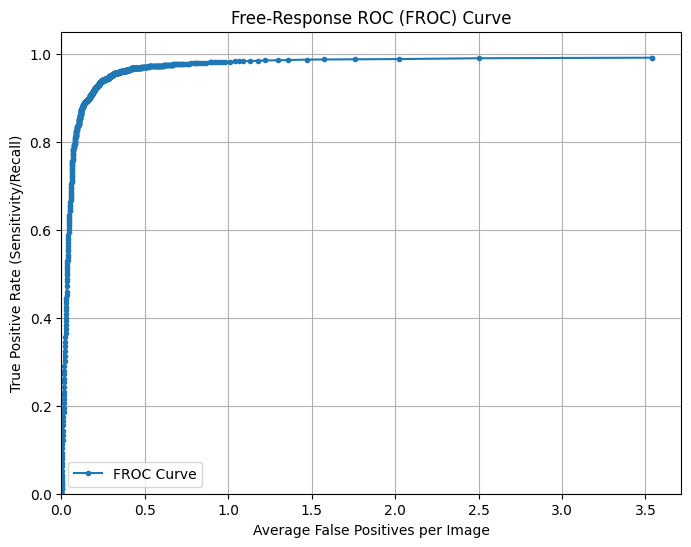